# 03 · Model Development (Phase 3)
**Deliverable:** three trained and compared models (Multinomial Naive Bayes, Logistic Regression, Linear SVM) + a chosen decision threshold.

### What this notebook does, in order
1. Define the cross-validation protocol (leakage-aware) and the metrics.
2. Feature experiment: unigrams vs unigrams+bigrams vs + handcrafted features.
3. Hyper-parameter tuning **inside** nested cross-validation (honest model comparison).
4. **Contribution 1** - quantify how much duplicates and template leakage inflate scores.
5. Sensitivity of results to the near-duplicate threshold.
6. Choose the decision threshold from *validation* (out-of-fold) scores.
7. Fit final development models on the full training set and save them.

**The held-out test set is NOT used anywhere in this notebook.** Everything below uses only the 515 training messages (`split == 'train'`).

## 0. Setup and protocol
### Cross-validation scheme - decisions
| Choice | Decision | Reasoning |
|---|---|---|
| Fold type | `StratifiedGroupKFold` | *Stratified* keeps the scam/legit ratio per fold; *Group* keeps each near-duplicate family inside one fold (no leakage). Plain `StratifiedKFold` would leak templates. |
| Folds | 5 | Each validation fold has ~100 messages: big enough to be meaningful, and each model trains on ~80% of the data. 10 folds would give ~50-message folds with very noisy metrics. |
| Repeats | 5 different shuffles for the feature experiment | With ~515 messages one split is noisy; repeating with different shuffles gives a more stable mean and an honest spread. (Repeated folds overlap, so the ± is an optimistic guide, not a true confidence interval - I treat differences below ~0.01 as noise.) |
| Positive class | scam | So recall/precision mean what the brief defines. |
| Threshold during CV | Default (0.5 probability for NB/LR; 0 margin for SVM) | Fair like-for-like comparison. Threshold is tuned separately in section 6. |

### Metrics
Accuracy, **scam recall**, **scam precision**, **F1**, **ROC-AUC** (brief section 9). ROC-AUC is threshold-free, so it is the **primary metric for choosing features and hyper-parameters**; recall/precision/F1 describe operating behaviour.

In [1]:
import sys; sys.path.insert(0, '..')   # makes src/ importable when the notebook runs from notebooks/
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, json, joblib, warnings
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from src.preprocessing import *
from src.train import build_pipeline, scam_score, tune, GRIDS, FEATURE_OPTIONS
from src.evaluation import *
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); pd.set_option('display.max_columns',None,'display.width',250,'display.max_colwidth',100)
d = pd.read_csv('../data/split.csv')
tr = d[d.split=='train'].reset_index(drop=True)
X, y, g = tr.message_content.values, tr.y.values, tr.group.values
print('training messages:', len(tr), '| scam share:', round(y.mean(),3))
def make_folds(seed, k=5, groups=g): 
    return list(StratifiedGroupKFold(k, shuffle=True, random_state=seed).split(X, y, groups))
REPEATS = [make_folds(s) for s in range(5)]
MODELS = {'nb':'Naive Bayes','lr':'Logistic Regression','svm':'Linear SVM'}

training messages: 515 | scam share: 0.584

## 1. Feature experiment (default hyper-parameters)
**Question (brief section 8):** does adding bigrams help? do the handcrafted features help? The three feature sets from notebook 02 are compared for each model with the *same* folds, so differences are due to the features only.

In [2]:
rows=[]
for m in MODELS:
    for name,(ng,hand) in {'A unigrams':((1,1),False),'B uni+bigrams':((1,2),False),'C uni+bi+handcrafted':((1,2),True)}.items():
        res = pd.concat([cv_fold_metrics(build_pipeline(m,ng,hand),X,y,f,m) for f in REPEATS])
        rows.append(dict(model=MODELS[m], features=name, **res[['accuracy','recall','precision','f1','roc_auc']].mean().round(3).to_dict(), auc_sd=round(res.roc_auc.std(),3)))
feat = pd.DataFrame(rows); feat.to_csv('../reports/feature_experiment.csv',index=False); feat

,model,features,accuracy,recall,precision,f1,roc_auc,auc_sd
0,Naive Bayes,A unigrams,0.820,0.922,0.801,0.856,0.922,0.030
1,Naive Bayes,B uni+bigrams,0.821,0.925,0.801,0.858,0.919,0.032
2,Naive Bayes,C uni+bi+handcrafted,0.819,0.940,0.791,0.859,0.927,0.030
3,Logistic Regression,A unigrams,0.877,0.931,0.868,0.898,0.943,0.022
4,Logistic Regression,B uni+bigrams,0.872,0.930,0.863,0.895,0.938,0.023
5,Logistic Regression,C uni+bi+handcrafted,0.894,0.912,0.909,0.910,0.953,0.018
6,Linear SVM,A unigrams,0.884,0.928,0.882,0.904,0.945,0.021
7,Linear SVM,B uni+bigrams,0.879,0.928,0.873,0.899,0.940,0.023
8,Linear SVM,C uni+bi+handcrafted,0.891,0.910,0.906,0.907,0.955,0.019


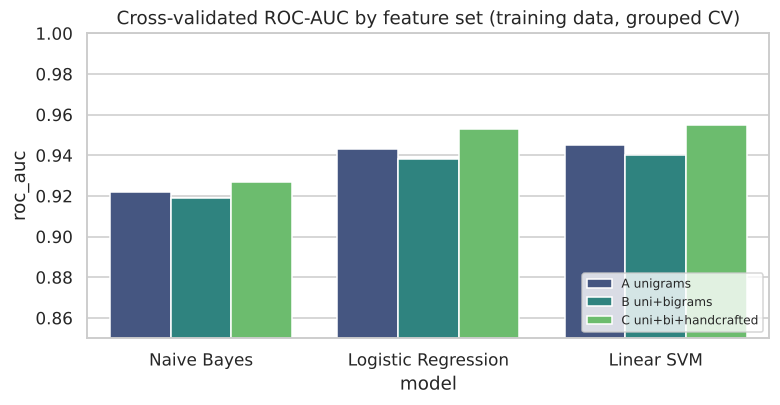

In [3]:
fig,ax=plt.subplots(figsize=(8,3.6))
sns.barplot(data=feat,x='model',y='roc_auc',hue='features',ax=ax,palette='viridis'); ax.set_ylim(0.85,1); ax.set_title('Cross-validated ROC-AUC by feature set (training data, grouped CV)'); ax.legend(fontsize=8,loc='lower right'); plt.show()

**Reading the result** (differences < ~0.01 are within noise at this sample size):
* **Naive Bayes is clearly the weakest** (AUC ~0.92-0.93 vs ~0.94-0.955 for the linear models, and F1 ~0.86 vs ~0.90-0.91) - as expected from a simple baseline whose independence assumption is strongly violated by bigrams.
* **Bigrams alone do not help** (A vs B are equal or slightly worse for all three models): with only ~500 messages, extra bigram features are mostly sparse and add noise.
* **Handcrafted features help modestly** (LR AUC 0.938 -> 0.953, SVM 0.940 -> 0.955, NB 0.919 -> 0.927) and make the fold-to-fold spread smaller.
* LR and SVM are nearly indistinguishable - expected, since both are linear margin-based classifiers on the same features.

This is an *exploratory* grid at default settings; the formal choice happens after tuning below. I keep all 4 feature options (including unigrams + handcrafted) in the tuning grid rather than pre-judging.

## 2. Hyper-parameter tuning with nested cross-validation
**Problem:** if I tune hyper-parameters on the same folds I then report, the score is optimistic (I picked the settings that happened to fit those folds). 
**Solution - nested CV:** an *outer* 5-fold loop gives honest performance; inside each outer training part an *inner* 4-fold loop does the entire search (feature option x hyper-parameters). The outer validation fold never influences any choice.

Search space (small and explicit - big grids overfit tiny datasets):
* feature options: unigrams / uni+bigrams, each with or without handcrafted features
* NB: `alpha` (smoothing) 0.1-1.0 · LR: `C` 0.5-16 and `class_weight` · SVM: `C` 0.1-3 and `class_weight`
* selection criterion: mean ROC-AUC; if options are within 0.002, **prefer the simpler one** (fewer features, stronger regularisation).

In [4]:
outer = make_folds(100)
nested_rows, chosen = [], []
for m in MODELS:
    for k,(a,b) in enumerate(outer):
        inner = list(StratifiedGroupKFold(4, shuffle=True, random_state=k).split(X[a], y[a], g[a]))
        cfg = tune(m, X[a], y[a], inner)
        p = build_pipeline(cfg['model'], tuple(cfg['ngram']), cfg['hand'], **cfg['params']).fit(X[a], y[a])
        nested_rows.append(dict(model=m, fold=k, **metrics(y[b], scam_score(p, X[b]), DEFAULT_THRESHOLD[m])))
        chosen.append(dict(model=m, fold=k, ngram=tuple(cfg['ngram']), hand=cfg['hand'], params=cfg['params']))
nested = pd.DataFrame(nested_rows); chosen = pd.DataFrame(chosen)
nested.to_csv('../reports/nested_cv_folds.csv', index=False)
summary = nested.groupby('model')[['accuracy','recall','precision','f1','roc_auc']].agg(['mean','std']).round(3)
summary

accuracy        recall        precision            f1        roc_auc       
          mean    std   mean    std      mean    std   mean    std    mean    std
model                                                                            
lr       0.886  0.037  0.897  0.040     0.907  0.037  0.901  0.033   0.952  0.022
nb       0.827  0.041  0.914  0.057     0.815  0.038  0.860  0.035   0.924  0.033
svm      0.891  0.031  0.897  0.040     0.916  0.036  0.906  0.028   0.952  0.023

In [5]:
print('Configuration chosen inside each outer fold (stability check):')
chosen

Configuration chosen inside each outer fold (stability check):

,model,fold,ngram,hand,params
0,nb,0,"(1, 1)",True,{'alpha': 0.1}
1,nb,1,"(1, 2)",True,{'alpha': 1.0}
2,nb,2,"(1, 1)",True,{'alpha': 0.1}
3,nb,3,"(1, 1)",True,{'alpha': 0.1}
4,nb,4,"(1, 1)",True,{'alpha': 0.1}
5,lr,0,"(1, 1)",True,"{'C': 16.0, 'class_weight': 'balanced'}"
6,lr,1,"(1, 1)",True,"{'C': 4.0, 'class_weight': None}"
7,lr,2,"(1, 1)",True,"{'C': 16.0, 'class_weight': 'balanced'}"
8,lr,3,"(1, 1)",True,"{'C': 16.0, 'class_weight': None}"
9,lr,4,"(1, 1)",True,"{'C': 16.0, 'class_weight': None}"


**Reading:** nested-CV ROC-AUC is ~0.952 for both LR and SVM and ~0.924 for NB. In *every* outer fold, every model chose **unigrams + handcrafted features** (bigrams were chosen only once, by NB), so the choice is stable. The nested numbers are the **honest cross-validated performance of "tune then fit"** for each model. The configuration picked inside each outer fold is shown to check *stability*: if a model picked wildly different settings per fold, its performance would be fragile.

### Pre-declared model-selection rule
(Stated before looking at the test set, to avoid choosing the winner by test score.)
1. Compare **nested-CV ROC-AUC**.
2. If two models are within **one standard error** (sd/sqrt(5)) of each other, the data cannot distinguish them, so prefer the more **interpretable** one in this order: Logistic Regression > Linear SVM > Naive Bayes. (LR gives calibrated-ish probabilities, which the app needs, and signed coefficients for explanation.)

In [6]:
se = nested.groupby('model').roc_auc.agg(['mean','std']).assign(se=lambda t: t['std']/np.sqrt(5)).round(4)
best = se['mean'].idxmax()
within = se[se['mean'] >= se.loc[best,'mean'] - se.loc[best,'se']].index.tolist()
print(se); print('\nbest by mean AUC:', best, '| statistically indistinguishable from best (within 1 SE):', within)
prefer = [m for m in ['lr','svm','nb'] if m in within][0]
print('SELECTED MODEL by the pre-declared rule ->', MODELS[prefer])

         mean     std      se
model                        
lr     0.9516  0.0223  0.0100
nb     0.9244  0.0333  0.0149
svm    0.9523  0.0235  0.0105

best by mean AUC: svm | statistically indistinguishable from best (within 1 SE): ['lr', 'svm']
SELECTED MODEL by the pre-declared rule -> Logistic Regression

## 3. Final tuned configuration per model
Now tune each model once on the **whole training set** (repeated grouped CV, 3 shuffles for stability) to get the configuration that will be (a) evaluated once on the test set in notebook 04 and (b) used for the app. The inner/outer separation above already told us honestly how good the procedure is; this step just produces the final settings.

In [7]:
tune_folds = make_folds(7) + make_folds(8) + make_folds(9)
final_cfg, tune_tables = {}, []
for m in MODELS:
    cfg, tab = tune(m, X, y, tune_folds, return_table=True)
    final_cfg[m] = cfg; tune_tables.append(tab)
    print(f"{MODELS[m]:20s} -> ngram={tuple(cfg['ngram'])}, handcrafted={cfg['hand']}, params={cfg['params']}")
tt = pd.concat(tune_tables); tt['params']=tt.params.astype(str); tt.to_csv('../reports/tuning_grid_results.csv', index=False)
top = tt.sort_values('roc_auc',ascending=False).groupby('model').head(3)[['model','ngram','hand','params','roc_auc','f1']].round(4); top

Naive Bayes          -> ngram=(1, 1), handcrafted=True, params={'alpha': 0.1}
Logistic Regression  -> ngram=(1, 1), handcrafted=True, params={'C': 16.0, 'class_weight': 'balanced'}
Linear SVM           -> ngram=(1, 1), handcrafted=True, params={'C': 1.0, 'class_weight': 'balanced'}

,model,ngram,hand,params,roc_auc,f1
21,svm,"(1, 1)",True,"{'C': 1.0, 'class_weight': 'balanced'}",0.9577,0.9093
20,svm,"(1, 1)",True,"{'C': 1.0, 'class_weight': None}",0.9576,0.9123
22,svm,"(1, 1)",True,"{'C': 3.0, 'class_weight': None}",0.9572,0.9133
23,lr,"(1, 1)",True,"{'C': 16.0, 'class_weight': 'balanced'}",0.9572,0.9116
22,lr,"(1, 1)",True,"{'C': 16.0, 'class_weight': None}",0.9571,0.9144
21,lr,"(1, 1)",True,"{'C': 4.0, 'class_weight': 'balanced'}",0.9562,0.9022
8,nb,"(1, 1)",True,{'alpha': 0.1},0.9280,0.8656
15,nb,"(1, 2)",True,{'alpha': 1.0},0.9272,0.8534
14,nb,"(1, 2)",True,{'alpha': 0.5},0.9253,0.8608


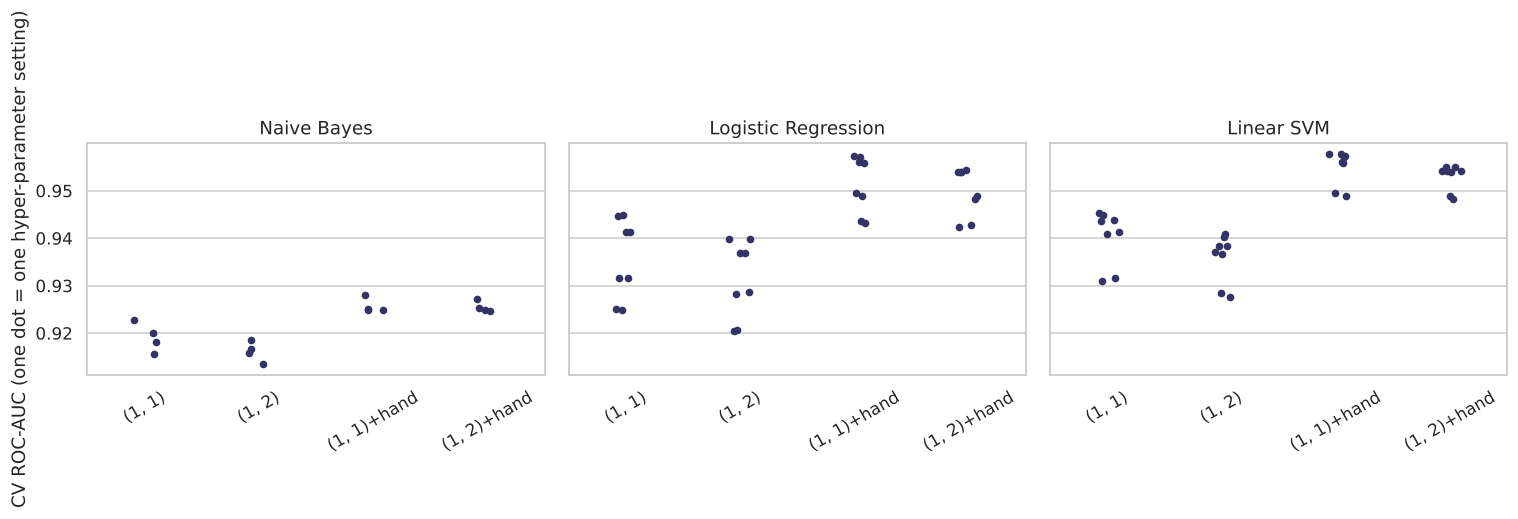

In [8]:
fig,axs=plt.subplots(1,3,figsize=(14,3.4),sharey=True)
for ax,m in zip(axs,MODELS):
    t = tt[tt.model==m].copy(); t['cfg']=t.ngram.astype(str)+np.where(t.hand,'+hand','')
    sns.stripplot(data=t,x='cfg',y='roc_auc',ax=ax,size=5,color='#336'); ax.set_title(MODELS[m]); ax.tick_params(axis='x',rotation=30); ax.set_xlabel('')
axs[0].set_ylabel('CV ROC-AUC (one dot = one hyper-parameter setting)'); plt.tight_layout(); plt.show()

**Reading:** each dot is one hyper-parameter setting. The *vertical spread inside a column* shows sensitivity to hyper-parameters (a flat band means the model is robust); the *difference between columns* shows the effect of the feature set. **All three models settled on unigrams + handcrafted features** - bigrams were never preferred, consistent with the feature experiment (with ~500 messages bigrams are too sparse to help; the brief asked us to *compare* them, and the answer is that they do not pay off here). The plateau of near-equal top scores is why the tie-breaking rule "prefer the simpler configuration" matters - many settings are statistically equivalent.

## 4. Contribution 1 - how much do duplicates and template leakage inflate performance?
The brief's key research question: *how reliably does the model perform on unseen messages when duplicates and leakage are controlled?* 
To answer, we evaluate the **same models** under four increasingly strict protocols, all on training-portion data:

| Protocol | Data | Splitting | What it represents |
|---|---|---|---|
| **P1 naive** | raw rows incl. exact duplicates | random stratified folds | what a careless analysis would do |
| **P2 exact-dedup** | raw rows | folds grouped by *identical text* | removes exact copies leakage but keeps them in the data |
| **P3 deduped, random** | cleaned unique messages | random stratified folds | duplicates removed, but template families can still straddle folds |
| **P4 deduped + grouped (ours)** | cleaned unique messages | folds grouped by near-duplicate family | our protocol |

The tuned configuration of each model (section 3) is used in all protocols so that only the protocol changes. (Raw rows used here are those whose text belongs to the training portion, so the test set is still untouched.)

In [9]:
raw = load_raw('../data/scam_detection_labeled.csv')
train_keys = set(tr.text_key)
rawtr = raw[raw.text_key.isin(train_keys)].reset_index(drop=True)
print('raw training-side rows:', len(rawtr), '(vs', len(tr), 'unique) -> duplicate rows:', len(rawtr)-len(tr))
Xr, yr = rawtr.message_content.values, rawtr.y.values
key2grp = {k:i for i,k in enumerate(rawtr.text_key.unique())}; gr_exact = rawtr.text_key.map(key2grp).values

def folds_for(proto, seed):
    if proto=='P1 naive (raw, random)':        return list(StratifiedKFold(5,shuffle=True,random_state=seed).split(Xr,yr)), Xr, yr
    if proto=='P2 exact-dedup groups (raw)':   return list(StratifiedGroupKFold(5,shuffle=True,random_state=seed).split(Xr,yr,gr_exact)), Xr, yr
    if proto=='P3 deduped, random folds':      return list(StratifiedKFold(5,shuffle=True,random_state=seed).split(X,y)), X, y
    if proto=='P4 deduped + near-dup groups':  return list(StratifiedGroupKFold(5,shuffle=True,random_state=seed).split(X,y,g)), X, y
PROTOS = ['P1 naive (raw, random)','P2 exact-dedup groups (raw)','P3 deduped, random folds','P4 deduped + near-dup groups']
rows=[]
for m in MODELS:
    c = final_cfg[m]; pipe = build_pipeline(m, tuple(c['ngram']), c['hand'], **c['params'])
    for pr in PROTOS:
        res=[]
        for s in range(10):
            f,Xp,yp = folds_for(pr, s); res.append(cv_fold_metrics(pipe,Xp,yp,f,m))
        res = pd.concat(res)
        rows.append(dict(model=MODELS[m], protocol=pr, **res[['accuracy','recall','precision','f1','roc_auc']].mean().round(3).to_dict()))
leak = pd.DataFrame(rows); leak.to_csv('../reports/leakage_experiment.csv',index=False)
leak.pivot(index='protocol',columns='model',values='f1').loc[PROTOS]

raw training-side rows: 591 (vs 515 unique) -> duplicate rows: 76

model,Linear SVM,Logistic Regression,Naive Bayes
protocol,,,
"P1 naive (raw, random)",0.924,0.923,0.879
P2 exact-dedup groups (raw),0.918,0.915,0.873
"P3 deduped, random folds",0.911,0.909,0.866
P4 deduped + near-dup groups,0.908,0.908,0.866


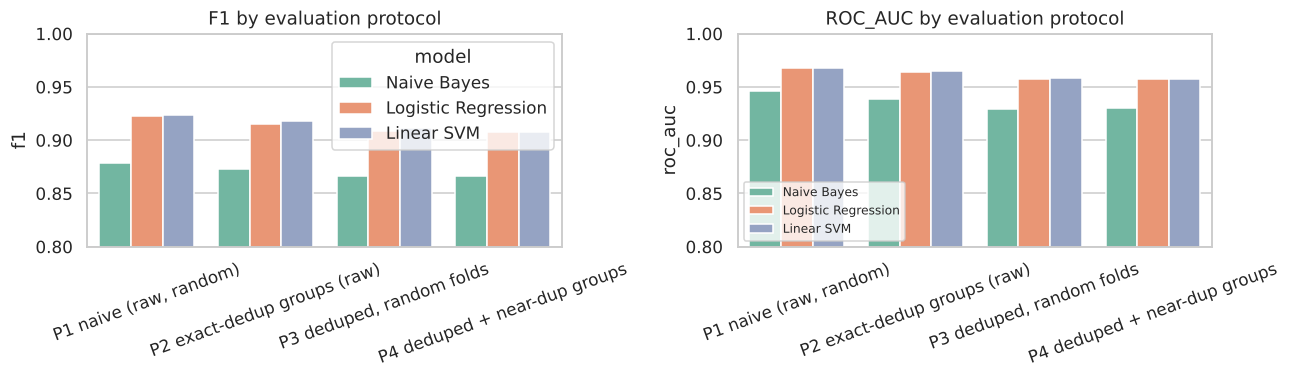

model
Linear SVM             0.016
Logistic Regression    0.015
Naive Bayes            0.013
Name: F1 inflation: naive minus ours, dtype: float64

In [10]:
fig,axs=plt.subplots(1,2,figsize=(12,3.6))
for ax,met in zip(axs,['f1','roc_auc']):
    sns.barplot(data=leak,x='protocol',y=met,hue='model',order=PROTOS,ax=ax,palette='Set2'); ax.set_ylim(0.8,1.0); ax.tick_params(axis='x',rotation=20); ax.set_xlabel(''); ax.set_title(met.upper()+' by evaluation protocol')
axs[1].legend(loc='lower left',fontsize=8); plt.tight_layout(); plt.show()
inflate = leak.pivot(index='model',columns='protocol',values='f1'); (inflate['P1 naive (raw, random)']-inflate['P4 deduped + near-dup groups']).round(3).rename('F1 inflation: naive minus ours')

**Interpretation.** Moving from the naive protocol (P1) to ours (P4) lowers every model's F1 by about **1.3-1.6 points** (e.g. LR 0.923 -> 0.908): the **leakage inflation**. It is *real but modest* here. Most of it comes from exact copies (P1 -> P2 -> P3: 0.923 -> 0.915 -> 0.909); extra grouping of near-duplicates (P3 -> P4) removes only ~0.001-0.003 more, i.e. template-variant leakage is small once exact repeats are gone. A modest effect is a legitimate finding: the dataset has only ~13% exact repeats and the linear models have limited capacity to memorise. Read it as an estimate with uncertainty (10 shuffles, ~500 messages), not an exact number - and note a high-capacity model (e.g. boosted trees) would likely show a larger gap. 

The headline for the research question: **the honest estimate is P4**, and all later results (notebook 04) are reported under it. Models are ranked the same way under every protocol (LR ~ SVM > NB), so the conclusion about *which model is best* is robust to the protocol, even though the *absolute* level is not.

## 5. Sensitivity to the near-duplicate threshold
I picked cosine 0.8 in notebook 01 as a judgement call. Does the conclusion depend on it? We regroup the training messages at different thresholds and re-run the selected configuration of each model (plus a "no grouping beyond exact text" baseline = P3).

In [11]:
rows=[]
for thr in [0.6,0.7,0.8,0.9,0.95]:
    gg = near_duplicate_groups(tr.message_content, thr)
    for m in MODELS:
        c = final_cfg[m]; pipe = build_pipeline(m, tuple(c['ngram']), c['hand'], **c['params'])
        res = pd.concat([cv_fold_metrics(pipe,X,y,list(StratifiedGroupKFold(5,shuffle=True,random_state=s).split(X,y,gg)),m) for s in range(6)])
        rows.append(dict(threshold=thr, n_groups=len(set(gg)), model=MODELS[m], f1=res.f1.mean(), roc_auc=res.roc_auc.mean()))
sens = pd.DataFrame(rows).round(3); sens.to_csv('../reports/sensitivity_grouping.csv',index=False)
p = sens.pivot(index='threshold',columns='model',values='roc_auc'); p.insert(0,'n_groups',sens.groupby('threshold').n_groups.first()); p

model,n_groups,Linear SVM,Logistic Regression,Naive Bayes
threshold,,,,
0.60,442,0.954,0.953,0.911
0.70,461,0.958,0.958,0.928
0.80,480,0.956,0.956,0.930
0.90,490,0.957,0.957,0.930
0.95,496,0.958,0.957,0.929


**Interpretation:** stricter grouping (lower threshold = bigger families kept together) removes more template leakage, so one might expect scores to fall - in fact they are essentially **flat** (LR AUC 0.953-0.958 across all thresholds; NB 0.911-0.930, with a dip only at 0.6), and the model ranking never changes. So the main conclusion does not hinge on the exact 0.8. (A caveat: lower thresholds also create odd folds with a few very large groups, which adds noise.)

## 6. Choosing the decision threshold (validation scores only)
### The trade-off
* A **missed scam** (false negative) can cost the user money.
* A **false alarm** (legit flagged) annoys the user and erodes trust, but - in our app, which only *warns* and does not delete or block - is much cheaper than a missed scam.

### Decision rule (stated up front)
> Choose the **highest threshold that still catches at least 95% of scams** on validation data. 

*Why 95%?* It is a policy choice, not a statistical truth: it says "we accept missing at most about 1 scam in 20". Raising the target would raise false alarms steeply (shown below); lowering it would miss too many scams for a safety tool. The target is an explicit parameter so a stakeholder can change it.
*Why "highest threshold meeting the target"?* Among thresholds that satisfy the recall target, the highest one gives the **fewest false alarms**.

### Validation data
**Out-of-fold (OOF) scores**: each training message is scored by a model that never saw it or its family (grouped 5-fold). The test set plays no role. (Small caveat: the hyper-parameters were tuned on these same training messages, so OOF scores are slightly optimistic; this is acknowledged in the limitations.)

In [12]:
oof, thr_sel = {}, {}
for m in MODELS:
    c = final_cfg[m]; pipe = build_pipeline(m, tuple(c['ngram']), c['hand'], **c['params'])
    # average OOF over 3 shuffles -> smoother, less lucky/unlucky threshold
    oof[m] = np.mean([oof_scores(pipe, X, y, make_folds(s), len(y)) for s in (21,22,23)], axis=0)
    thr_sel[m] = choose_threshold(y, oof[m], 0.95)
rows=[]
for m in MODELS:
    for name,t in [('default',DEFAULT_THRESHOLD[m]),('selected (recall>=95%)',thr_sel[m])]:
        mm = metrics(y, oof[m], t); rows.append(dict(model=MODELS[m], threshold_rule=name, threshold=round(t,3), recall=mm['recall'], precision=mm['precision'], f1=mm['f1'], missed_scams=mm['fn'], false_alarms=mm['fp']))
thr_tab = pd.DataFrame(rows).round(3); thr_tab

,model,threshold_rule,threshold,recall,precision,f1,missed_scams,false_alarms
0,Naive Bayes,default,0.500,0.914,0.826,0.868,26,58
1,Naive Bayes,selected (recall>=95%),0.315,0.950,0.792,0.864,15,75
2,Logistic Regression,default,0.500,0.920,0.923,0.922,24,23
3,Logistic Regression,selected (recall>=95%),0.320,0.950,0.894,0.921,15,34
4,Linear SVM,default,0.000,0.920,0.920,0.920,24,24
5,Linear SVM,selected (recall>=95%),-0.222,0.950,0.897,0.923,15,33


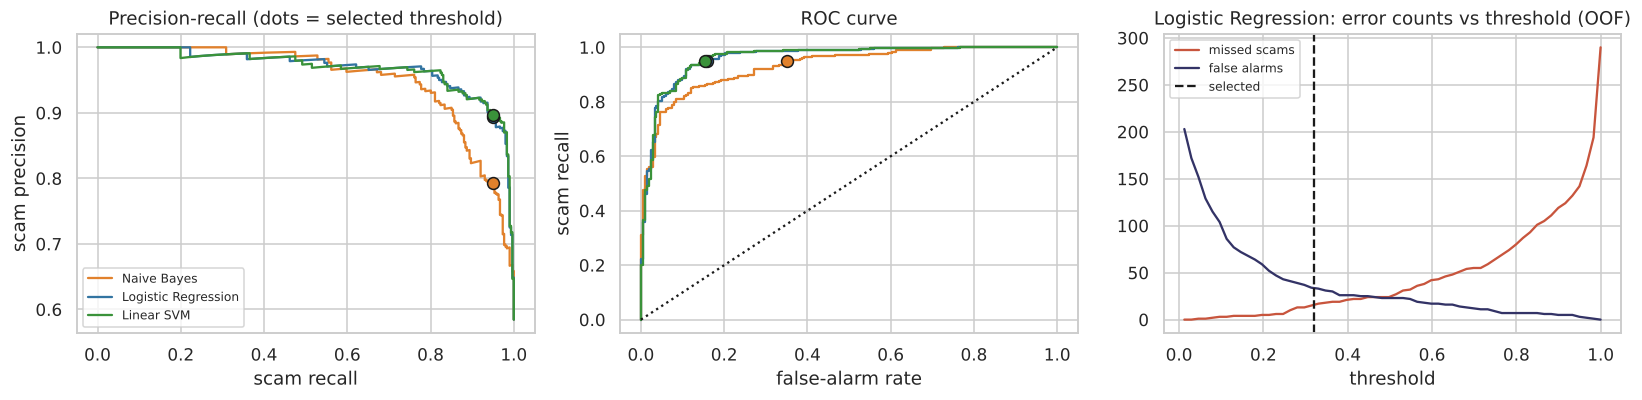

In [13]:
from sklearn.metrics import precision_recall_curve, roc_curve
fig,axs=plt.subplots(1,3,figsize=(15,3.8))
for m,col in zip(MODELS,['#e1812c','#3274a1','#3a923a']):
    pr,rc,th = precision_recall_curve(y,oof[m]); axs[0].plot(rc,pr,label=MODELS[m],color=col)
    fpr,tpr,_ = roc_curve(y,oof[m]); axs[1].plot(fpr,tpr,label=MODELS[m],color=col)
    mm = metrics(y,oof[m],thr_sel[m]); axs[0].scatter(mm['recall'],mm['precision'],color=col,s=60,edgecolor='k',zorder=5); axs[1].scatter(mm['fp']/(mm['fp']+mm['tn']),mm['recall'],color=col,s=60,edgecolor='k',zorder=5)
axs[0].set_xlabel('scam recall'); axs[0].set_ylabel('scam precision'); axs[0].set_title('Precision-recall (dots = selected threshold)')
axs[1].plot([0,1],[0,1],'k:'); axs[1].set_xlabel('false-alarm rate'); axs[1].set_ylabel('scam recall'); axs[1].set_title('ROC curve'); axs[0].legend(fontsize=8)
sel = prefer; ts = np.linspace(np.percentile(oof[sel],2), np.percentile(oof[sel],98), 60); tt_ = threshold_table(y,oof[sel],ts)
axs[2].plot(tt_.threshold,tt_.missed_scams,color='#c8553d',label='missed scams'); axs[2].plot(tt_.threshold,tt_.false_alarms,color='#336',label='false alarms'); axs[2].axvline(thr_sel[sel],color='k',ls='--',label='selected'); axs[2].set_title(f'{MODELS[sel]}: error counts vs threshold (OOF)'); axs[2].set_xlabel('threshold'); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [14]:
sel = prefer
tab = threshold_table(y, oof[sel], np.round(np.quantile(oof[sel], [0.2,0.3,0.4,0.5,0.6]),3).tolist()+[round(thr_sel[sel],3), 0.5 if sel!='svm' else 0.0])
tab.drop_duplicates('threshold').sort_values('threshold').round(3)

,threshold,recall,precision,f1,missed_scams,false_alarms
0,0.081,0.993,0.726,0.839,2,113
1,0.183,0.987,0.823,0.897,4,64
5,0.320,0.950,0.894,0.921,15,34
2,0.375,0.937,0.913,0.925,19,27
6,0.500,0.920,0.923,0.922,24,23
3,0.706,0.817,0.953,0.880,55,12
4,0.858,0.661,0.966,0.785,102,7


**Reading:** for the selected Logistic Regression, the 95%-recall threshold is ~0.32 (instead of 0.5): out-of-fold it misses **15** scams (vs 24 at the default) at the cost of **34** false alarms (vs 23). The table shows the dial. Moving the threshold down catches more scams but flags more legit messages; the selected threshold sits where recall reaches 95%. Compared with the default threshold, the selected one deliberately trades some precision for recall - this is the explicit, justified trade-off the brief asks for. In **absolute counts on ~515 messages** the cost of the extra recall is shown in the `false_alarms` column.

**Reminder on prevalence:** precision here is measured on a dataset where 58% of messages are scams. In a real inbox scams are a small minority, so real-world precision at the same threshold would be lower - the app's wording should say "possible scam", not "scam".

## 7. Fit final development models on the full training set and save
Each model is fitted on all 515 training messages with its tuned configuration and its selected threshold. (The **final deployment model** - fitted on *all* 643 messages - is created at the end of notebook 04, after the test set has been used once.)

In [15]:
dev = {}
for m in MODELS:
    c = final_cfg[m]
    pipe = build_pipeline(m, tuple(c['ngram']), c['hand'], **c['params']).fit(X, y)
    dev[m] = dict(pipeline=pipe, config=dict(c, threshold=thr_sel[m], default_threshold=DEFAULT_THRESHOLD[m], name=MODELS[m]))
joblib.dump(dev, '../models/dev_models.joblib')
pd.DataFrame(oof).assign(y=y, group=g, message_content=X).to_csv('../reports/oof_scores_train.csv', index=False)
sel_info = dict(selected_model=prefer, selection_rule='nested-CV ROC-AUC; ties within 1 SE -> LR > SVM > NB', target_recall=0.95,
                thresholds={m:float(v) for m,v in thr_sel.items()}, configs=final_cfg)
json.dump(sel_info, open('../models/selection.json','w'), indent=1, default=str)
print('saved. selected:', MODELS[prefer]); sel_info['configs'][prefer]

saved. selected: Logistic Regression

{'model': 'lr', 'ngram': [1, 1], 'hand': True, 'params': {'C': 16.0, 'class_weight': 'balanced'}}

## 8. Summary of decisions in this notebook
| Decision | Choice | Reason |
|---|---|---|
| CV scheme | Stratified + grouped 5-fold (repeated) | Class balance kept; template families never straddle folds |
| Primary selection metric | ROC-AUC | Threshold-free; the operating point is chosen separately |
| Tuning | Nested CV, small explicit grids, tie -> simpler | Honest estimate; avoids overfitting 515 messages |
| Feature sets | Tuned per model among uni/uni+bi x with/without handcrafted | Let evidence, not preference, decide |
| Model selection | Pre-declared rule (1-SE, then interpretability) | Avoids picking a winner by luck or by test score |
| Leakage study | P1->P4 protocols; threshold sensitivity | Brief's research contribution 1 |
| Threshold | Highest threshold with OOF recall >= 95% | Missed scams cost more than false alarms in a warn-only app; explicit & adjustable |

**Next:** notebook 04 evaluates the three tuned models **once** on the held-out test set, analyses errors, inspects coefficients and builds the final deployment model.